# P10 - Modélisation des ventes d'un ensemble de magasin

## Objectifs
- Caractériser les différentes typologies de magasin de l'enseigne en fonction des caractéristiques de vente et de l'environnement du magasin
- Construire un modèle de prévision des ventes basique puis grâce à des méthodes de prévision des séries temporelles
- Évaluer la performance des modèles sur un magasin par groupe

In [1]:
  #Importation des librairies
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans

In [2]:
#Affichage de toutes les colonnes d'un dataframe
pd.options.display.max_columns = None
pd.options.display.max_rows = None
pd.options.display.float_format = "{:.2f}".format

# 1. Exploration des données

## 1.1 Chargement des données

In [3]:
#Importation des fichiers
df_store = pd.read_csv("store.csv")
df_train = pd.read_csv("train.csv")

/tmp/ipykernel_524/1474526940.py:3: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df_train = pd.read_csv("train.csv")


- ***STORE***

In [4]:
#Dimensions du dataset
print("Le DF comporte {} ligne(s)".format(df_store.shape[0]))
print("Le DF comporte {} colonnes(s)".format(df_store.shape[1]))

Le DF comporte 1115 ligne(s)
Le DF comporte 10 colonnes(s)


In [5]:
#Nature des données
df_store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assortment                 1115 non-null   object 
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    object 
dtypes: float64(5), int64(2), object(3)
memory usage: 87.2+ KB


In [6]:
#5 premières lignes du DF
df_store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN


**df_store = typologie des magasins**



- ***TRAIN***

In [7]:
#Dimensions du dataset
print("Le DF comporte {} ligne(s)".format(df_train.shape[0]))
print("Le DF comporte {} colonnes(s)".format(df_train.shape[1]))

Le DF comporte 1017209 ligne(s)
Le DF comporte 9 colonnes(s)


In [8]:
#Nature des données
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB


- **ANOMALIE 1** : Date au format object --> à modifier au format datetime pour l'analyse des données temporelles

In [9]:
#Correction de l'Anomalie 2 :
df_train["Date"] = pd.to_datetime(df_train["Date"])
#Vérification ed la correction
df_train["Date"].dtype

dtype('<M8[ns]')

In [10]:
#5 premières lignes du DF
df_train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


**df_train = historique des ventes**

## 1.2 Vérification de la qualité des données

- ***STORE***

In [11]:
df_store.describe()

,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00,1112.00,761.00,761.00,1115.00,571.00,571.00
mean,558.00,5404.90,7.22,2008.67,0.51,23.60,2011.76
std,322.02,7663.17,3.21,6.20,0.50,14.14,1.67
min,1.00,20.00,1.00,1900.00,0.00,1.00,2009.00
25%,279.50,717.50,4.00,2006.00,0.00,13.00,2011.00
50%,558.00,2325.00,8.00,2010.00,1.00,22.00,2012.00
75%,836.50,6882.50,10.00,2013.00,1.00,37.00,2013.00
max,1115.00,75860.00,12.00,2015.00,1.00,50.00,2015.00


In [12]:
#Vérification des doublons de Store (ID unique pour chaque magasin)
print("Doublons de 'Store' : {}".format(df_store.duplicated("Store").sum()))

Doublons de 'Store' : 0


In [13]:
df_store.nunique()

,0
Store,1115
StoreType,4
Assortment,3
CompetitionDistance,654
CompetitionOpenSinceMonth,12
CompetitionOpenSinceYear,23
Promo2,2
Promo2SinceWeek,24
Promo2SinceYear,7
PromoInterval,3


In [14]:
#Vérification des valeurs distinctes :
print("Valeurs distinctes de 'StoreType' : {}".format(df_store ["StoreType"].unique()))
print("Valeurs distinctes de 'Assortment' : {}".format(df_store ["Assortment"].unique()))
print("Valeurs distinctes de 'CompetitionOpenSinceMonth' : {}".format(df_store ["CompetitionOpenSinceMonth"].unique()))
print("Valeurs distinctes de 'Promo2' : {}".format(df_store ["Promo2"].unique()))
print("Valeurs distinctes de 'CompetitionOpenSinceYear' : {}".format(df_store ["CompetitionOpenSinceYear"].unique()))
print("Valeurs distinctes de 'Promo2SinceYear' : {}".format(df_store ["Promo2SinceYear"].unique()))
print("Valeurs distinctes de 'PromoInterval' : {}".format(df_store ["PromoInterval"].unique()))

Valeurs distinctes de 'StoreType' : ['c' 'a' 'd' 'b']
Valeurs distinctes de 'Assortment' : ['a' 'c' 'b']
Valeurs distinctes de 'CompetitionOpenSinceMonth' : [ 9. 11. 12.  4. 10.  8. nan  3.  6.  5.  1.  2.  7.]
Valeurs distinctes de 'Promo2' : [0 1]
Valeurs distinctes de 'CompetitionOpenSinceYear' : [2008. 2007. 2006. 2009. 2015. 2013. 2014. 2000. 2011.   nan 2010. 2005.
 1999. 2003. 2012. 2004. 2002. 1961. 1995. 2001. 1990. 1994. 1900. 1998.]
Valeurs distinctes de 'Promo2SinceYear' : [  nan 2010. 2011. 2012. 2009. 2014. 2015. 2013.]
Valeurs distinctes de 'PromoInterval' : [nan 'Jan,Apr,Jul,Oct' 'Feb,May,Aug,Nov' 'Mar,Jun,Sept,Dec']


In [15]:
#Vérification des valeurs atypiques de la variable 'CompetitionOpenSinceYear'
df_store.loc[df_store['CompetitionOpenSinceYear'] <1950]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
814,815,a,a,590.00,1.00,1900.00,1,40.00,2014.00,"Jan,Apr,Jul,Oct"


- **ANOMALIE 2** : 1 magasin présente une année d'ouverture du concurrent le proche = à 1900 , erreur de saisie ?

In [16]:
#Vérification des valeurs manquantes
print(df_store.isnull().sum())

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64


In [17]:
#Tableau des valeurs manquantse par colonne
missing_values = df_store.isnull().sum()
missing_percent = (missing_values / len(df_store)) *  100
missing_table = pd.DataFrame( {'Missing Values' : missing_values, 'Percentage' : missing_percent})
print(missing_table)

                           Missing Values  Percentage
Store                                   0        0.00
StoreType                               0        0.00
Assortment                              0        0.00
CompetitionDistance                     3        0.27
CompetitionOpenSinceMonth             354       31.75
CompetitionOpenSinceYear              354       31.75
Promo2                                  0        0.00
Promo2SinceWeek                       544       48.79
Promo2SinceYear                       544       48.79
PromoInterval                         544       48.79


In [18]:
df_store.describe()

,Store,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear
count,1115.00,1112.00,761.00,761.00,1115.00,571.00,571.00
mean,558.00,5404.90,7.22,2008.67,0.51,23.60,2011.76
std,322.02,7663.17,3.21,6.20,0.50,14.14,1.67
min,1.00,20.00,1.00,1900.00,0.00,1.00,2009.00
25%,279.50,717.50,4.00,2006.00,0.00,13.00,2011.00
50%,558.00,2325.00,8.00,2010.00,1.00,22.00,2012.00
75%,836.50,6882.50,10.00,2013.00,1.00,37.00,2013.00
max,1115.00,75860.00,12.00,2015.00,1.00,50.00,2015.00


In [19]:
#Vérification des valeurs manquantes de 'Promo2SinceWeek',  'Promo2SinceYear',  'PromoInterval'
df_store['Promo2'].value_counts()

,count
Promo2,
1,571
0,544


- Promo2 = 1 : 571 magasins participent à la promotion continue
- Promo2 = 0 : 544 magasins n'y participent pas      

In [20]:
#Vérification que les 544 valeurs manquantes des variables 'Promo2SinceWeek',  'Promo2SinceYear',  'PromoInterval' correspondent bien au 544 magasins qui ne participent pas à la promotion continue (Promo2 = 0)
print("nb de ligne manquantes pour les variables 'Promo2SinceWeek' pour  Promo2 = 0 : {}".format(df_store.loc[(df_store['Promo2']==0)&(df_store['Promo2SinceWeek'].isna())].shape[0]))
print("nb de ligne manquantes pour les variables 'Promo2SinceYear' pour  Promo2 = 0 : {}".format(df_store.loc[(df_store['Promo2']==0)&(df_store['Promo2SinceYear'].isna())].shape[0]))
print("nb de ligne manquantes pour les variables 'PromoInterval' pour  Promo2 = 0 : {}".format(df_store.loc[(df_store['Promo2']==0)&(df_store['PromoInterval'].isna())].shape[0]))

nb de ligne manquantes pour les variables 'Promo2SinceWeek' pour  Promo2 = 0 : 544
nb de ligne manquantes pour les variables 'Promo2SinceYear' pour  Promo2 = 0 : 544
nb de ligne manquantes pour les variables 'PromoInterval' pour  Promo2 = 0 : 544


- Pas d'anomalies pour ces 544 valeurs manquantes, puisqu'il s'agit de magasins ne participant pas à la promotion continue

In [21]:
#Vérification des valeurs manquantes des 3 lignes de 'CompetitionDistance'
df_store.loc[df_store['CompetitionDistance'].isna()]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.00,2013.00,"Feb,May,Aug,Nov"


- **ANOMALIE 3** : 3 magasins sur 1 115 ont une distance au concurrent le plus proche non renseignée. Ces 3 magasins n'ont peut-etre pas de concurrent proche et représentent 0.27% des données donc peu d'impact. Je choisi de ne pas réaliser d'imputation.

In [22]:
#Vérification des valeurs manquantes des 353 lignes de 'CompetitionOpenSinceMonth    '
df_store.loc[df_store['CompetitionOpenSinceMonth'].isna()].head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
11,12,a,c,1070.00,NaN,NaN,1,13.00,2010.00,"Jan,Apr,Jul,Oct"
12,13,d,a,310.00,NaN,NaN,1,45.00,2009.00,"Feb,May,Aug,Nov"
15,16,a,c,3270.00,NaN,NaN,0,NaN,NaN,NaN
18,19,a,c,3240.00,NaN,NaN,1,22.00,2011.00,"Mar,Jun,Sept,Dec"
21,22,a,a,1040.00,NaN,NaN,1,22.00,2012.00,"Jan,Apr,Jul,Oct"


In [23]:
#Vérification si les valeurs manquantes du mois et de l'année concernent les mêmes magasins
df_store.loc[df_store['CompetitionDistance'].notna() & df_store['CompetitionOpenSinceMonth'].isna() & df_store['CompetitionOpenSinceYear'].isna()].shape[0]

351

- **ANOMALIE 4** : 351 magasins ont une distance au concurrent le plus proche renseigné mais le mois et l'année d'ouverture du magasin concurrent sont manquants (soit 31% de manquants). 'CompetitionOpenSinceYear' et 'CompetitionOpenSinceMonth' ont une corrélation de 1 dans la heatmap, ces 2 valeurs manquent toujours ensemble. Je n'ai pas trouvé de variable qui peut aider à prédire une date d'ouverture, il n y'aura donc pas d'imputation et les valeurs resteront en 'NaN'.

- ***TRAIN***

In [24]:
df_train.dtypes

,0
Store,int64
DayOfWeek,int64
Date,datetime64[ns]
Sales,int64
Customers,int64
Open,int64
Promo,int64
StateHoliday,object
SchoolHoliday,int64


In [25]:
df_train.describe()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,SchoolHoliday
count,1017209.00,1017209.00,1017209,1017209.00,1017209.00,1017209.00,1017209.00,1017209.00
mean,558.43,4.00,2014-04-11 01:30:42.846061824,5773.82,633.15,0.83,0.38,0.18
min,1.00,1.00,2013-01-01 00:00:00,0.00,0.00,0.00,0.00,0.00
25%,280.00,2.00,2013-08-17 00:00:00,3727.00,405.00,1.00,0.00,0.00
50%,558.00,4.00,2014-04-02 00:00:00,5744.00,609.00,1.00,0.00,0.00
75%,838.00,6.00,2014-12-12 00:00:00,7856.00,837.00,1.00,1.00,0.00
max,1115.00,7.00,2015-07-31 00:00:00,41551.00,7388.00,1.00,1.00,1.00
std,321.91,2.00,NaN,3849.93,464.41,0.38,0.49,0.38


In [26]:
df_train.sort_values('Date').head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
1017208,1115,2,2013-01-01,0,0,0,0,a,1
1016473,379,2,2013-01-01,0,0,0,0,a,1
1016472,378,2,2013-01-01,0,0,0,0,a,1
1016471,377,2,2013-01-01,0,0,0,0,a,1
1016470,376,2,2013-01-01,0,0,0,0,a,1


In [27]:
#Vérification des valeurs distinctes :
print("Valeurs distinctes de 'DayOfWeek' : {}".format(df_train ["DayOfWeek"].unique()))
print("Valeurs distinctes de 'Promo' : {}".format(df_train ["Promo"].unique()))
print("Valeurs distinctes de 'StateHoliday' : {}".format(df_train ["StateHoliday"].unique()))
print("Valeurs distinctes de 'SchoolHoliday' : {}".format(df_train ["SchoolHoliday"].unique()))

Valeurs distinctes de 'DayOfWeek' : [5 4 3 2 1 7 6]
Valeurs distinctes de 'Promo' : [1 0]
Valeurs distinctes de 'StateHoliday' : ['0' 'a' 'b' 'c' 0]
Valeurs distinctes de 'SchoolHoliday' : [1 0]


In [28]:
###################################
###Analyse de la variable 'Open'###
###################################
print("Valeurs distinctes de 'Open' : {}".format(df_train ["Open"].unique()))

#Vérification des valeurs de la variables 'Sales'. Règle, si 'Open' =0 alors 'Sales' = 0
df_train.loc[(df_train["Open"] == 0) & (df_train["Sales"] > 0)]

Valeurs distinctes de 'Open' : [1 0]


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


In [29]:
#Vérifions les magasins ouverts 'Open' =1 qui ont des ventes inférieurs ou égale à 0
df_train.loc[(df_train["Open"] == 1) & (df_train["Sales"] == 0)].head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
86825,971,5,2015-05-15,0,0,1,0,0,1
142278,674,4,2015-03-26,0,0,1,0,0,0
196938,699,4,2015-02-05,0,0,1,1,0,0
322053,708,3,2014-10-01,0,0,1,1,0,0
330176,357,1,2014-09-22,0,0,1,0,0,0


In [30]:
df_train.loc[(df_train["Open"] == 1) & (df_train["Sales"] == 0)].shape[0]

54

Conclusion suite de analyse variable 'Open' :
- il n y'a pas d'anomalies, les magasins fermés ('Open' = 0) n'ont pas de ventes.
- il y'a 54 observation journalières avec un CA nul alors que le magasin est ouvert ('Open' = 1)

In [31]:
###################################
###Analyse de la variable 'Date'###
###################################

#contrôle des données temporelles : Est-ce que toutes les dates sont converties correctement et y'a-t-il des dates manquantes ?
print("format de la variable 'Date' : {}".format(df_train["Date"].dtype))
print("le Min et Max de la variable 'Date' sont : {}".format((df_train['Date'].min(), df_train['Date'].max())))
print("Dates invalides :", df_train["Date"].isna().sum())

format de la variable 'Date' : datetime64[ns]
le Min et Max de la variable 'Date' sont : (Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))
Dates invalides : 0


La variable 'Date' est au format datetime, aucune date n'est manquante et la période du data set couvre les données du 01/01/2013 au 31/07/2015

In [32]:
#contrôle des données temporelles : Ai-je une seule valeur par date ?
print("Doublons du couple 'Store/Date' : {}".format(df_train.duplicated(["Store", 'Date']).sum()))

Doublons du couple 'Store/Date' : 0


Une ligne correspond à un CA à une date donnée pour un magasin. Il n'y a aucun doublon sur le couple Store/Date.

In [33]:
#contrôle des données temporelles : la série est-elle continue sur la fréquence choisie pour chaque magasin?
df_train.groupby('Date') ['Store'].nunique().head()

,Store
Date,
2013-01-01,1114
2013-01-02,1115
2013-01-03,1115
2013-01-04,1115
2013-01-05,1115


In [34]:
#Vérification du nombre de jour entre le 1er jour de vente dans le dataset et le dernier :
from datetime import datetime
date_format = "%m/%d/%Y"

a = datetime.strptime('01/01/2013', date_format)
b = datetime.strptime('07/31/2015', date_format)

delta = b - a

print("Nous devrions trouver {} jours pour chaque magasin".format(delta.days+1) )

Nous devrions trouver 942 jours pour chaque magasin


In [35]:
#Vérification de la répartition des magasins selon le nombre de jours de données
df_train.groupby('Store') ['Date'].nunique().value_counts()

,count
Date,
942,934
758,180
941,1


- 934 magasins ont 942 dates distinctes, la série est donc complète et continue pour ces 934 magasins.

**ANOMALIE 5** :
- 180 magasins ont 758 dates distinctes : il manque 184 jours de données par  rapport aux 942 jours attendus.

**ANOMALIE 6** :
- 1 magasin a 941 dates distinctes. : il manque 1 jour de donnée par rapport aux 942 jrs attendus.

In [36]:
#Identification des dates manquantes pour les 180 magasins dont la série temporelle est incomplète
df_serie_incomplete_180 = df_train.groupby('Date') ['Store',].nunique()
df_serie_incomplete_180 = df_serie_incomplete_180.loc[(df_serie_incomplete_180["Store"] != 1115) &  (df_serie_incomplete_180["Store"] != 1114)].reset_index()
print("le Min et Max de la variable 'Date' de df_serie_incomplete_180 sont : {}".format((df_serie_incomplete_180['Date'].min(), df_serie_incomplete_180['Date'].max())))

le Min et Max de la variable 'Date' de df_serie_incomplete_180 sont : (Timestamp('2014-07-01 00:00:00'), Timestamp('2014-12-31 00:00:00'))


In [37]:
#Identification de la date manquante pour le magasins dont la série temporelle est incomplète
df_serie_incomplete_1 = df_train.groupby('Date') ['Store',].nunique()
df_serie_incomplete_1 = df_serie_incomplete_1.loc[df_serie_incomplete_1["Store"] == 1114].reset_index()
print("le Min et Max de la variable 'Date' de df_serie_incomplete_1 sont : {}".format((df_serie_incomplete_1['Date'].min(), df_serie_incomplete_1['Date'].max())))

le Min et Max de la variable 'Date' de df_serie_incomplete_1 sont : (Timestamp('2013-01-01 00:00:00'), Timestamp('2013-01-01 00:00:00'))


In [38]:
#Identification des numéros d'ID unique des 180 magasins dont la série temporelle est incomplète
df_serie_incomplete_mag_180 = df_train.loc[(df_train['Date'] >= '2014-07-01 00:00:00') & (df_train['Date'] <= '2014-12-31 00:00:00')| (df_train['Date'] == '2013-02-01 00:00:00') , ['Store', 'Date']]
df_serie_incomplete_mag_180 = df_serie_incomplete_mag_180.pivot_table(index = 'Store', values= 'Date', aggfunc= 'count')
df_serie_incomplete_mag_180.value_counts()

,count
Date,
185,935
1,180


In [39]:
#Affichage des numéros d'ID unique des 180 magasins dont la série temporelle est incomplète entre le 01/07/2014 et 31/12/2014
df_serie_incomplete_mag_180.loc[df_serie_incomplete_mag_180 ['Date']== 1].head()

,Date
Store,
13,1
20,1
22,1
32,1
36,1


In [40]:
#Identification des numéro d'ID unique du magasin dont la série temporelle est incomplète
df_serie_incomplete_mag_1 = df_train.loc[(df_train['Date'] == '2013-01-01 00:00:00') | (df_train['Date'] == '2013-02-01 00:00:00'), ['Store', 'Date']]
df_serie_incomplete_mag_1 = df_serie_incomplete_mag_1.pivot_table(index = 'Store', values= 'Date', aggfunc= 'count').reset_index()
df_serie_incomplete_mag_1.loc[df_serie_incomplete_mag_1['Date'] != 2]

,Store,Date
987,988,1


Conclusion : anomalie 5 et 6
- Anomalie 5 : pour les 180 magasins, je vais pousser l'analyse pour vérifier l'impact sur le CA et sur l'évolution du CA
- Anomalie 6 : pour le magasin ID 988 pour lequel il manque une observation au 01/01/2013. S'agissant d'une ligne manquante sur 1017209 présent dans ce Dataset, il y'aura un impact  quasi nul sur l'analyse. Je décide de garder ce magasin et de ne pas réaliser d'imputation.

## 1.3 Nettoyage et préparation du jeu de données pour l'analyse

In [41]:
#Ajout d'une colonne "Donnees_temporelles_incompletes" pour identifier dans le dataset complet les magasins avec des données temporelles incomplètes
df_serie_incomplete_mag_180 = df_serie_incomplete_mag_180.loc[df_serie_incomplete_mag_180 ['Date']== 1]
df_serie_incomplete_mag_180['Donnees_temporelles_incompletes'] = 'Oui'
df_serie_incomplete_mag_180.head()

,Date,Donnees_temporelles_incompletes
Store,,
13,1,Oui
20,1,Oui
22,1,Oui
32,1,Oui
36,1,Oui


In [42]:
df_serie_incomplete_mag_180 = df_serie_incomplete_mag_180.reset_index()
df_serie_incomplete_mag_180 = df_serie_incomplete_mag_180.loc[:, ['Store', 'Donnees_temporelles_incompletes']]
df_serie_incomplete_mag_180.head()

,Store,Donnees_temporelles_incompletes
0,13,Oui
1,20,Oui
2,22,Oui
3,32,Oui
4,36,Oui


In [43]:
#Jonction des fichiers df_store et df_train
#Dimensions du dataset avant fusion
print("Le tableau comporte {} ligne(s)".format(df_train.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_train.shape[1]))
#Fusion des fichiers df_erp et df_liaison
df_merge_train_store = pd.merge(df_train,df_store,on="Store",how="inner")
df_merge_train_store.head()

Le tableau comporte 1017209 ligne(s)
Le tableau comporte 9 colonne(s)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN


In [44]:
#Vérification des dimensions du dataset après fusion
print("Le tableau comporte {} ligne(s)".format(df_merge_train_store.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge_train_store.shape[1]))

Le tableau comporte 1017209 ligne(s)
Le tableau comporte 18 colonne(s)


In [45]:
#Jonction des fichiers df_merge_train_store et df_serie_incomplete_mag_180
df_merge = pd.merge(df_merge_train_store,df_serie_incomplete_mag_180,on="Store",how="left")

df_merge.head()


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Donnees_temporelles_incompletes
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",NaN
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",NaN
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,NaN


In [46]:
#Vérification des dimensions du dataset après fusion
print("Le tableau comporte {} ligne(s)".format(df_merge.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge.shape[1]))

Le tableau comporte 1017209 ligne(s)
Le tableau comporte 19 colonne(s)


In [47]:
#Vérification du rapport entre Nb de magasin total du dataset et 180 magasins avec valeurs manquantes
Nb_Store_All = df_merge['Store'].nunique()
Select_Nb_Store_180 = df_merge[df_merge['Donnees_temporelles_incompletes'].notna()]
Nb_Store_180 = Select_Nb_Store_180['Store'].nunique()
print("Les 180 magasins avec valeurs manquantes  représentent {:.0f} % des magasins présents dans le Dataset ".format(Nb_Store_180 / Nb_Store_All *100))

Les 180 magasins avec valeurs manquantes  représentent 16 % des magasins présents dans le Dataset 


In [48]:
#Vérification du poids des ventes des 180 mag par rapport à l'ensemble des ventes
Sales_all = df_merge['Sales'].sum()
Select_180 = df_merge[df_merge['Donnees_temporelles_incompletes'].notna()]
Sales_180 = Select_180['Sales'].sum()
print("Le CA des 180 magasins  représente {:.0f} % du CA total".format(Sales_180 / Sales_all *100))

Le CA des 180 magasins  représente 13 % du CA total


In [49]:
#Création de 2 DF pour vérifier l'impacte des 180 magasins dans la série temporelle
df_merge_all = df_merge.loc[:,['Store','Date', 'Sales', 'Customers', 'StoreType' ]]
df_merge_Time_serie_complet = df_merge.loc[df_merge['Donnees_temporelles_incompletes'].isna(),['Store','Date', 'Sales', 'Customers', 'StoreType' ]]

In [50]:
#Comparaison de l'évolution du CA des 2 DF : somme du CA
evolution_ca_all  = df_merge_all.groupby(["Date"])["Sales"].sum()
evolution_ca_Time_serie_complet   = df_merge_Time_serie_complet.groupby(["Date"])["Sales"].sum()

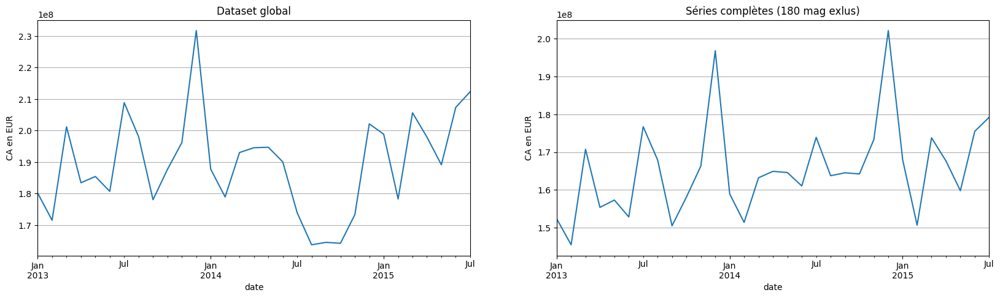

In [51]:
#Comparaison de l'évolution mensuelle du CA des 2 DF
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)

evolution_ca_all.resample('ME').sum().plot(title='Dataset global')
plt.xlabel('date')
plt.grid(axis ='y')
plt.ylabel('CA en EUR')

plt.subplot(1, 2, 2)
evolution_ca_Time_serie_complet.resample('ME').sum().plot(title='Séries complètes (180 mag exlus)')
plt.xlabel('date')
plt.grid(axis ='y')
plt.ylabel('CA en EUR')

plt.show()

La comparaison des 2 DF montre une différence importante dans l'évolution du CA. Le creux observé de juillet 2014 jusqu'à janvier coincide avec la période de données manquantes des 180 magasins.  Vérifions si nous retrouvons cette différence dans l'évolution du CA mensuelle moyen

In [52]:
#Comparaison de l'évolution du CA des 2 DF : Moyenne quotidienne du CA
evolution_ca_all_mean  = df_merge_all.groupby(["Date"])["Sales"].mean()
evolution_ca_Time_serie_complet_mean   = df_merge_Time_serie_complet.groupby(["Date"])["Sales"].mean()

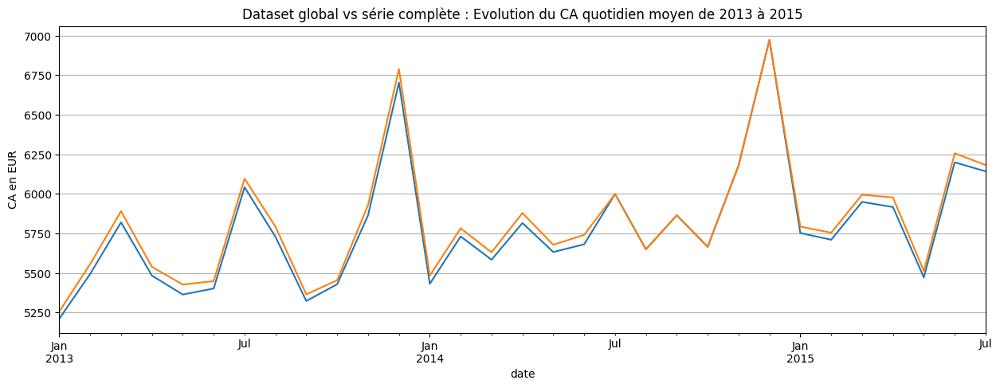

In [53]:
plt.figure(figsize=(15, 5))
plt.title('Dataset global vs série complète : Evolution du CA quotidien moyen de 2013 à 2015')

evolution_ca_all_mean.resample('ME').mean().plot()
evolution_ca_Time_serie_complet_mean.resample('ME').mean().plot()
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')

En comparant l'évolution du CA mensuel moyen, le creux de juillet a disparu. Les deux datasets présentent des pics et des creux très proche.
En conclusion, l'exclusion des 180 magasins a peu d'impact visible sur l'évolution du CA moyen mensuel. Afin de travailler sur une série temporelle complète et continue et de construire le modèle de prévision dans de bonnes conditions, je choisis de supprimer les données des 180 magasins du dataset.

In [54]:
#Préparation des DataFrame pour la suite de l'étude
#DF ventes CA quotidien évolution :
df_analyse = df_merge.loc[df_merge['Donnees_temporelles_incompletes'].isna(),:].copy()
df_analyse = df_analyse.drop(columns='Donnees_temporelles_incompletes')

In [55]:
df_analyse.head(10)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN
5,6,5,2015-07-31,5651,589,1,1,0,1,a,a,310.00,12.00,2013.00,0,NaN,NaN,NaN
6,7,5,2015-07-31,15344,1414,1,1,0,1,a,c,24000.00,4.00,2013.00,0,NaN,NaN,NaN
7,8,5,2015-07-31,8492,833,1,1,0,1,a,a,7520.00,10.00,2014.00,0,NaN,NaN,NaN
8,9,5,2015-07-31,8565,687,1,1,0,1,a,c,2030.00,8.00,2000.00,0,NaN,NaN,NaN
9,10,5,2015-07-31,7185,681,1,1,0,1,a,a,3160.00,9.00,2009.00,0,NaN,NaN,NaN


## 1.4 Description de la distribution statistique

In [56]:
print(df_analyse["Sales"].describe())

count   880769.00
mean      5825.39
std       3898.90
min          0.00
25%       3723.00
50%       5780.00
75%       7928.00
max      38722.00
Name: Sales, dtype: float64


In [57]:
#Distribution statistique par type de magasin (DF complet)
px.box(df_analyse,x="StoreType",y="Sales",title="Distribution du CA par type de magasin")

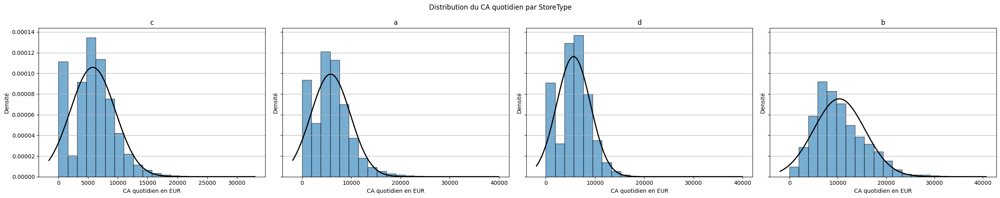

In [58]:
from scipy.stats import norm
import numpy as np
groups = df_analyse.groupby("StoreType",sort=False)

fig, axes = plt.subplots(1, 4, figsize=(25, 5), sharey=True)

for (product, df), ax in zip(groups, axes):
    ax.hist(df["Sales"], bins=20, density=True, edgecolor="black", alpha=0.6)
    ax.set_title(product)
    ax.set_xlabel("CA quotidien en EUR")
    ax.set_ylabel("Densité")
    ax.grid(axis ='y')
    #Ajustement gaussien
    mu, std = norm.fit(df["Sales"])
    xmin, xmax = ax.get_xlim()
    x = np.linspace(xmin, xmax, df.shape[0])
    p = norm.pdf(x, mu, std)
    ax.plot(x, p, "k", linewidth=2)

plt.suptitle("Distribution du CA quotidien par StoreType")
plt.tight_layout()

plt.show()

- La moyenne du CA quotidien est de 5825.39 EUR et la médiane 5780 EUR. l' Écart type sur l'ensemble du dataset est de 3898.90 EUR ce qui signifie que la dispersion des ventes est forte, avec une variation importante d'une vente à l'autre.
- Les boxplot par type de magasin montrent que les types a, c et d ont une distribution similaire. Le type b a une médiane plus élevé et une distribution plus dispersé.
- Les histogrammes montrent des distributions asymétriques à droites. Les distributions ne suivent pas la courbe de Gauss et ne semblent donc pas suivre une loi normale

Conclusion : nous observons 2 profils de magasins. Magasins de Type a, c et d qui ont des CA médians proches et type b qui réalisent un CA plus élévé. Ces 2 types devront etre pris en compte pour la construction du modèle de prévision.

# 2. Caractérisez les différentes typologies de magasin

## 2.1 Comparaison des volumes de vente au mois et à l'année des magasins

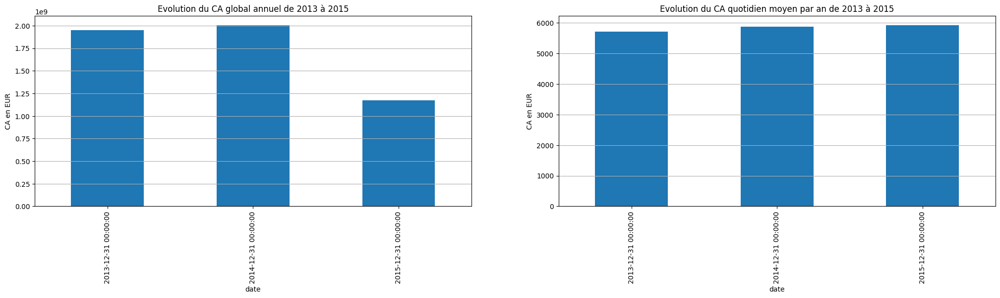

In [59]:
#Evolution du CA par an
plt.figure(figsize=(25, 5))
plt.subplot(1, 2, 1)
df = df_analyse.groupby("Date")["Sales"].sum()
df.resample ('YE').sum().plot(kind='bar')
plt.title('Evolution du CA global annuel de 2013 à 2015')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')


plt.subplot(1, 2, 2)
df = df_analyse.groupby("Date")["Sales"].mean()
df.resample ('YE').mean().plot(kind='bar')
plt.title('Evolution du CA quotidien moyen par an de 2013 à 2015')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')

plt.show()

L'évolution du CA global annuel met en évidence une tendance légère à la hausse du CA globale entre 2013 et 2014. A noter que l'année 2015 est incomplète et s'arrête au 31/07/2015. L'évolution du CA quotidien moyen montre également une évolution entre 2013 et 2015

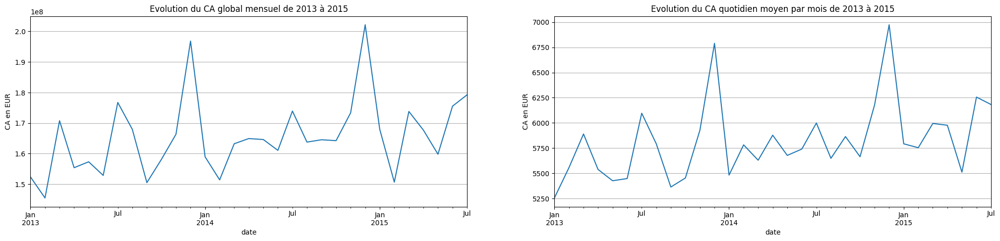

In [60]:
#Evolution du CA par mois
plt.figure(figsize=(25, 5))
plt.subplot(1, 2, 1)
df = df_analyse.groupby("Date")["Sales"].sum().copy()
df.resample ('ME').sum().plot()
plt.title('Evolution du CA global mensuel de 2013 à 2015')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')


plt.subplot(1, 2, 2)
df = df_analyse.groupby("Date")["Sales"].mean().copy()
df.resample ('ME').mean().plot()
plt.title('Evolution du CA quotidien moyen par mois de 2013 à 2015')
plt.xlabel('date')
plt.ylabel('CA en EUR')
plt.grid(axis ='y')

plt.show()

L'évolution mensuelle met en évidence des pics et des creux qui se répétent chaque année à la même période : exemple pic en juillet et en décembre.

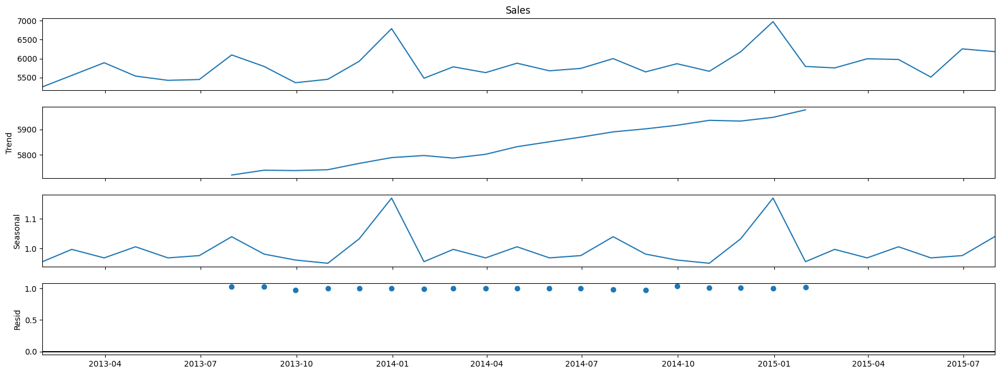

In [61]:
#Affichons la décomposition de la série pour voir s'il existe un effet saisonnier
from statsmodels.tsa.seasonal import seasonal_decompose
df_decompose = df.resample ('ME').mean().copy()
decompose_result_mult = seasonal_decompose(df_decompose, model='multiplicative')
trend = decompose_result_mult.trend
seasonal = decompose_result_mult.seasonal
residual = decompose_result_mult.resid
decompose_result_mult.plot().set_size_inches(20, 7);

In [62]:
#Affichage du coef saisonnier :
seasonal.groupby(seasonal.index.month).mean()

,seasonal
Date,
1,0.96
2,1.00
3,0.97
4,1.01
5,0.97
6,0.98
7,1.04
8,0.98
9,0.96


Nous observons une légère tendance à la hausse sur l'ensemble du data set. La décomposition de la série confirme qu'il y'a un effet saisonnier marqué en décembre avec un pic(le CA de dec varie de +17% par rapport à la moyenne annuel)  et un petit pic en juillet qui se répetent chaque année. Nous observons aussi un petit creux en octobre (le CA varie de -5% par rapport à la moyenne annuel en octobre)

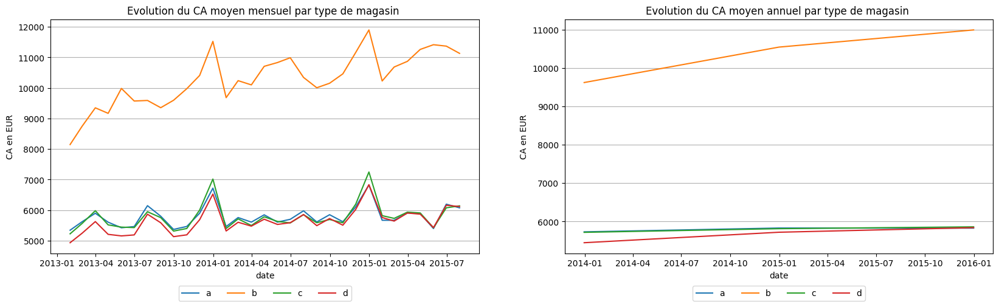

In [63]:
#Evolution du CA global par mois et par type de magasin

groups_store = df_analyse.groupby("StoreType")
plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
for StoreType, df in groups_store:
    evol = df.groupby("Date")["Sales"].mean()
    plt.plot(evol.resample ('ME').mean(), label = StoreType)
    plt.title('Evolution du CA moyen mensuel par type de magasin ')
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
    plt.xlabel('date')
    plt.ylabel('CA en EUR')
plt.grid(axis ='y')

plt.subplot(1, 2, 2)
for StoreType, df in groups_store:
    evol = df.groupby("Date")["Sales"].mean()
    plt.plot(evol.resample ('YE').mean(), label = StoreType)
    plt.title('Evolution du CA moyen annuel par type de magasin ')
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)
    plt.xlabel('date')
    plt.ylabel('CA en EUR')
plt.grid(axis ='y')

plt.show()

L'évolution du CA moyen par type de magasin met en évidence 2 profils distincts :

- Magasins a, c et d : ils suivent la même tendance globale. Le CA moyen annuel est relativement stable (en dessous de 6000EUR). L'évolution du CA moyen mensuel suit également les mêmes variations, avec pour ces 3 types une amplitude similaire (entre 5000EUR et 7000EUR). Pics en décembre et petit pic en juillet.

- Magasin de type b : il évolue seul. Son CA moyen annuel est nettement supérieur à celui des 3 autres types de magasins, avec une progression constante (entre 9500EUR et 11000EUR). Le CA moyen mensuel présente des variations plus marquées, avec 2 pics visibles chaque année autour décembre.

In [64]:
#Ajout variable année et mois
df_analyse["annee"] = df_analyse["Date"].dt.year
df_analyse["mois"] = df_analyse["Date"].dt.month

In [65]:
#CA de vente global par année
ca_annee = df_analyse.groupby("annee")["Sales"].sum()
print("Le CA par année est de {}".format(ca_annee))

Le CA par année est de annee
2013    1950440366
2014    2005894733
2015    1174483697
Name: Sales, dtype: int64


In [66]:
df_analyse.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,annee,mois
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,2015,7
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",2015,7
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",2015,7
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,2015,7
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,2015,7


In [67]:
#Evolution du CA global
evolution_ca = (ca_annee[2014]-ca_annee[2013])/ca_annee[2013]*100
print (evolution_ca)

2.8431716225052734


In [68]:
#Evolution du CA par Stortype
df_ca_annee = df_analyse.pivot_table ( index = "StoreType", columns='annee', values= 'Sales',aggfunc='sum')
df_ca_annee['taux_Evolution_13_vs_14'] = (df_ca_annee[2014]-df_ca_annee[2013]) / df_ca_annee[2013] *100
df_ca_annee.sort_values('taux_Evolution_13_vs_14', ascending=False)

annee,2013,2014,2015,taux_Evolution_13_vs_14
StoreType,,,,
b,56213035,61609248,37303433,9.60
d,530928730,557554643,330588981,5.01
a,1083606265,1102372269,640071245,1.73
c,279692336,284358573,166520038,1.67


In [69]:
#Total CA par type de magasin
ca_global = df_analyse["Sales"].sum()
print("Le CA global sur la période d'analyse est de {} EUR".format(ca_global))

df_total_sales = df_analyse.groupby('StoreType')['Sales'].sum().sort_values(ascending=False).reset_index()
#Création colonne de la part du CA du type de magasin
df_total_sales["Part_CA_%"] = df_total_sales["Sales"] / ca_global *100
df_total_sales.head()

Le CA global sur la période d'analyse est de 5130818796 EUR


,StoreType,Sales,Part_CA_%
0,a,2826049779,55.08
1,d,1419072354,27.66
2,c,730570947,14.24
3,b,155125716,3.02


In [70]:
#Nb de magasin par Type*
df_nb = df_analyse.groupby("StoreType")["Store"].nunique()
df_nb.head()

,Store
StoreType,
a,518
b,16
c,134
d,267


In [71]:
#CA moyen par type
df_ca_moyen = df_analyse.groupby(['StoreType', 'Store'])['Sales'].sum().groupby('StoreType').mean()
df_ca_moyen.head()

,Sales
StoreType,
a,5455694.55
b,9695357.25
c,5452021.99
d,5314877.73


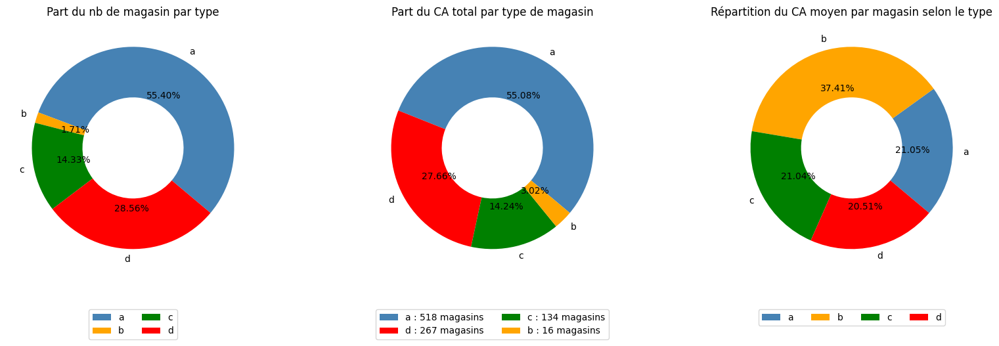

In [72]:
couleurs = {'a': 'steelblue', 'b': 'orange', 'c': 'green', 'd': 'red'}
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.pie(x=df_nb.values, labels=df_nb.index, colors=[couleurs[i] for i in df_nb.index], autopct='%.2f%%', wedgeprops=dict(width=0.5), startangle=-40)
plt.title('Part du nb de magasin par type')
plt.legend( loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

labels_nb_ca = ["a : 518 magasins", "d : 267 magasins", "c : 134 magasins", "b : 16 magasins"]
plt.subplot(1, 3, 2)
plt.pie(x=df_total_sales['Part_CA_%'], labels=df_total_sales['StoreType'],colors=[couleurs[i] for i in df_total_sales['StoreType']], autopct='%.2f%%', wedgeprops=dict(width=0.5), startangle=-40)
plt.title('Part du CA total par type de magasin')
plt.legend(labels=labels_nb_ca, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.subplot(1, 3, 3)
plt.pie( x=df_ca_moyen.values,labels=df_ca_moyen.index, colors=[couleurs[i] for i in df_ca_moyen.index],  autopct='%.2f%%', wedgeprops=dict(width=0.5), startangle=-40)
plt.title('Répartition du CA moyen par magasin selon le type')
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5)

plt.show()

- StoreType a : majorité des magasins (55 %) et génère 55% du CA.
- StoreType b : seulement 16 magasins (1,7 %), mais génère 3,02 % du CA. Son CA moyen par magasin est supérieur aux autres types.
- StoreType c : 14% des magasin et génère la même proportion de CA
- StoreType d : représente 28,4 % des magasins et génère 27,66 % du CA.


La répartition du CA Suit globalement celle du NB de magasins pour les types a, c et d. Le type b a toutefois un CA moyen par magasin supérieur aux autres types.

## 2.2 Paramètres influants sur le volume de vente (régression linéaire)

In [73]:
#DF ventes CA qutodien moyen par store
df_regression = df_analyse.groupby(['Store', 'StoreType']).agg({'Sales': ['mean'],'Customers': ['mean']}).reset_index()
df_regression = df_regression.copy()
df_regression.columns = ['_'.join(col) for col in df_regression.columns] #passage de multi index à 1d
df_regression.head()

,Store_,StoreType_,Sales_mean,Customers_mean
0,1,c,3945.70,467.65
1,2,a,4122.99,486.05
2,3,a,5741.25,620.29
3,4,c,8021.77,1100.06
4,5,a,3867.11,444.36


Coefficient de corrélation de Pearson : 0.852
Valeur p : 1.29e-264


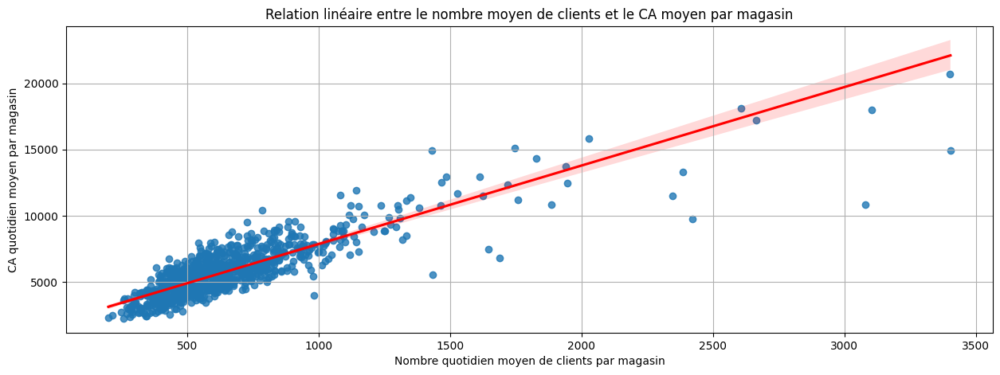

In [74]:
from scipy.stats import pearsonr
# Visualisation de la tendance
plt.figure(figsize=(15, 5))
sns.regplot( data=df_regression, x='Customers_mean', y='Sales_mean', robust=True,line_kws=dict(color="r"))

plt.xlabel("Nombre quotidien moyen de clients par magasin")
plt.ylabel("CA quotidien moyen par magasin")
plt.title("Relation linéaire entre le nombre moyen de clients et le CA moyen par magasin")
plt.grid()
correlation, p_value = pearsonr(df_regression['Customers_mean'].values, df_regression['Sales_mean'].values)
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

In [75]:
#Création de 4 DF par storeType
df_regression_a = df_regression.loc[df_regression['StoreType_']=='a']
df_regression_b = df_regression.loc[df_regression['StoreType_']=='b']
df_regression_c = df_regression.loc[df_regression['StoreType_']=='c']
df_regression_d = df_regression.loc[df_regression['StoreType_']=='d']

Coefficient de corrélation de Pearson : 0.920
Valeur p : 5.17e-212


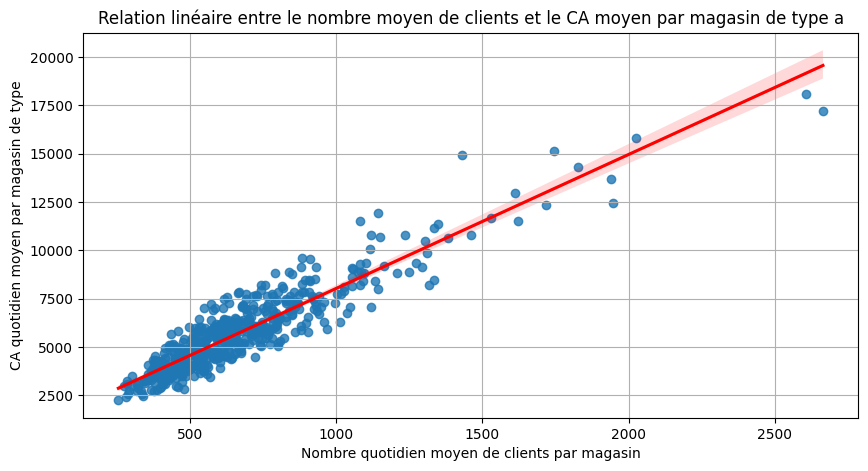

In [76]:
from scipy.stats import pearsonr
# Visualisation de la tendance
plt.figure(figsize=(10, 5))

sns.regplot( data=df_regression_a, x='Customers_mean', y='Sales_mean', robust=True,line_kws=dict(color="r"))

plt.xlabel("Nombre quotidien moyen de clients par magasin")
plt.ylabel("CA quotidien moyen par magasin de type")
plt.title("Relation linéaire entre le nombre moyen de clients et le CA moyen par magasin de type a")
plt.grid()
correlation, p_value = pearsonr(df_regression_a['Customers_mean'].values, df_regression_a['Sales_mean'].values)
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

Coefficient de corrélation de Pearson : 0.878
Valeur p : 7.87e-06


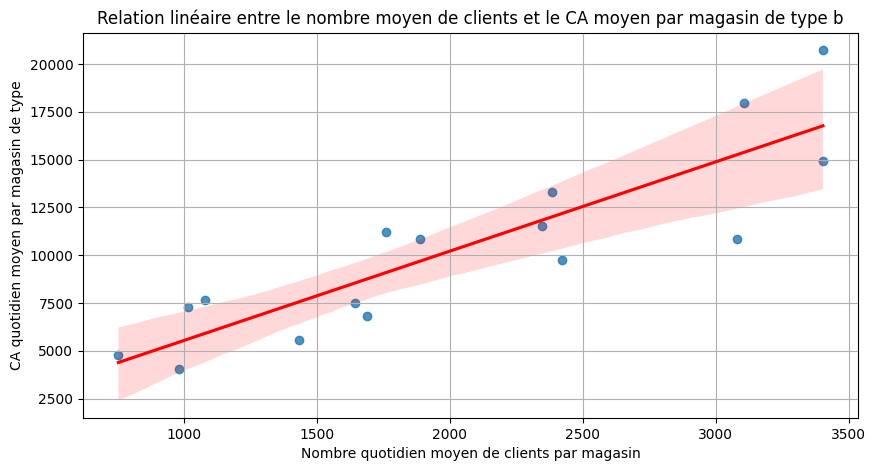

In [77]:
from scipy.stats import pearsonr
# Visualisation de la tendance
plt.figure(figsize=(10, 5))

sns.regplot( data=df_regression_b, x='Customers_mean', y='Sales_mean', robust=True,line_kws=dict(color="r"))

plt.xlabel("Nombre quotidien moyen de clients par magasin")
plt.ylabel("CA quotidien moyen par magasin de type")
plt.title("Relation linéaire entre le nombre moyen de clients et le CA moyen par magasin de type b")
plt.grid()
correlation, p_value = pearsonr(df_regression_b['Customers_mean'].values, df_regression_b['Sales_mean'].values)
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

Coefficient de corrélation de Pearson : 0.899
Valeur p : 3.77e-49


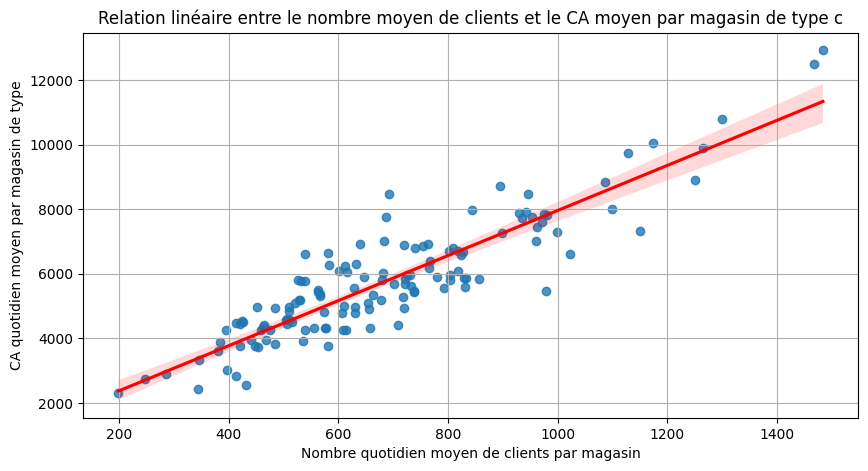

In [78]:
from scipy.stats import pearsonr
# Visualisation de la tendance
plt.figure(figsize=(10, 5))

sns.regplot( data=df_regression_c, x='Customers_mean', y='Sales_mean', robust=True,line_kws=dict(color="r"))

plt.xlabel("Nombre quotidien moyen de clients par magasin")
plt.ylabel("CA quotidien moyen par magasin de type")
plt.title("Relation linéaire entre le nombre moyen de clients et le CA moyen par magasin de type c")
plt.grid()
correlation, p_value = pearsonr(df_regression_c['Customers_mean'].values, df_regression_c['Sales_mean'].values)
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

Coefficient de corrélation de Pearson : 0.825
Valeur p : 9.68e-68


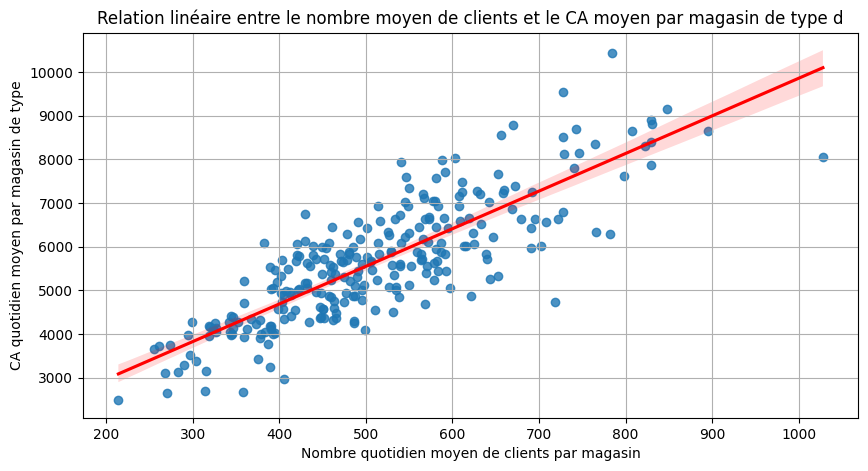

In [79]:
from scipy.stats import pearsonr
# Visualisation de la tendance
plt.figure(figsize=(10, 5))

sns.regplot( data=df_regression_d, x='Customers_mean', y='Sales_mean', robust=True,line_kws=dict(color="r"))

plt.xlabel("Nombre quotidien moyen de clients par magasin")
plt.ylabel("CA quotidien moyen par magasin de type")
plt.title("Relation linéaire entre le nombre moyen de clients et le CA moyen par magasin de type d")
plt.grid()
correlation, p_value = pearsonr(df_regression_d['Customers_mean'].values, df_regression_d['Sales_mean'].values)
print(f"Coefficient de corrélation de Pearson : {correlation:.3f}")
print(f"Valeur p : {p_value:.2e}")

- Ensemble des magasin : Coef de corrélation de Pearson = 0.852 et valeur p proche de 0.
- les magasins de type a présentent un Coef de corrélation de Pearson le  plus fort = 0.920 suivi de mag type c (0.899) et type b (0.878) et le pus faible est le magasin de type d avec un un coef de corrélation de 0.825. La valeur p est proche de 0 pour les 4 types de magasins. Ces indicateurs confirment qu'il existe une forte relation linéaire positive entre le nombre quotidien moyen de clients et le CA quotidien moyen par magasin.

## 2.3 Catégorisation des magasins grâce à K-means selon différents critères

In [80]:
#Préparation des données avec critères issus du CA quotidien (filtre sur Open ==1 pour obtenir les indicateurs de perfo des magasins)
df_open = df_analyse.loc[df_analyse['Open'] == 1].copy()
df_sales = df_open.groupby(['Store']).agg({'Sales': ['sum', 'mean', 'std'],'Customers': ['sum', 'mean']}).reset_index()
df_sales= df_sales.copy()
df_sales.columns = [''.join(col) for col in df_sales.columns] #passage de multi index à 1d
#Création colonne panier moyen
df_sales["PanierMoyen"] = df_sales["Salessum"] / df_sales["Customerssum"]
#Création colonne Coef de variation
df_sales["Coef_Var_CA_quotidien"] = df_sales["Salesstd"] / df_sales["Salesmean"] *100
df_sales.head()

,Store,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien
0,1,3716854,4759.10,1012.11,440523,564.05,8.44,21.27
1,2,3883858,4953.90,1610.15,457855,584.00,8.48,32.50
2,3,5408261,6942.57,2193.38,584310,750.08,9.26,31.59
3,4,7556507,9638.40,1936.03,1036254,1321.75,7.29,20.09
4,5,3642818,4676.27,1765.75,418588,537.34,8.70,37.76


In [81]:
#Ajout sales et panier moyen sous promo
df_promo = df_open.loc[df_open['Promo'] == 1]
df_promo = df_promo.groupby(['Store']).agg({'Sales': ['sum', 'mean'], 'Customers': ['sum']}).reset_index()

df_promo= df_promo.copy()
df_promo.columns = [''.join(col) for col in df_promo.columns] #passage de multi index à 1d
#Création colonne panier moyen
df_promo["PanierMoyen_promo"] = df_promo["Salessum"] / df_promo["Customerssum"]

df_promo = df_promo.rename(columns= {'Salessum' : 'Sales_Promo'})
df_promo = df_promo.rename(columns= {'Salesmean' : 'Salesmean_Promo'})
df_promo = df_promo.drop(columns= {'Customerssum'})
df_promo.head()

,Store,Sales_Promo,Salesmean_Promo,PanierMoyen_promo
0,1,1855039,5300.11,8.92
1,2,2222214,6277.44,9.10
2,3,3099120,8854.63,10.11
3,4,3733384,10576.16,7.61
4,5,2139936,6096.68,9.33


In [82]:
#Ajout sales et panier moyen hors promo
df__hors_promo = df_open.loc[df_open['Promo'] == 0]
df__hors_promo = df__hors_promo.groupby(['Store']).agg({'Sales': ['mean']}).reset_index()

df__hors_promo= df__hors_promo.copy()
df__hors_promo.columns = [''.join(col) for col in df__hors_promo.columns] #passage de multi index à 1d


df__hors_promo = df__hors_promo.rename(columns= {'Salesmean' : 'Salesmean_hors_Promo'})

df__hors_promo.head()

,Store,Salesmean_hors_Promo
0,1,4319.76
1,2,3864.29
2,3,5382.61
3,4,8870.35
4,5,3511.41


In [83]:
#Jonction des fichiers df_store et df_sales
#Dimensions du dataset avant fusion
print("Le tableau comporte {} ligne(s)".format(df_store.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_store.shape[1]))
#Fusion des fichiers
df_merge1 = pd.merge(df_store,df_sales,on="Store",how="inner")
df_merge1.head()

Le tableau comporte 1115 ligne(s)
Le tableau comporte 10 colonne(s)


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,3716854,4759.10,1012.11,440523,564.05,8.44,21.27
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",3883858,4953.90,1610.15,457855,584.00,8.48,32.50
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",5408261,6942.57,2193.38,584310,750.08,9.26,31.59
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,7556507,9638.40,1936.03,1036254,1321.75,7.29,20.09
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,3642818,4676.27,1765.75,418588,537.34,8.70,37.76


In [84]:
#Jonction des fichiers df_merge1 et df_promo
#Dimensions du dataset avant fusion
print("Le tableau comporte {} ligne(s)".format(df_merge1.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge1.shape[1]))
#Fusion des fichiers
df_merge2 = pd.merge(df_merge1,df_promo,on="Store",how="inner")
df_merge2.head()

Le tableau comporte 935 ligne(s)
Le tableau comporte 17 colonne(s)


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien,Sales_Promo,Salesmean_Promo,PanierMoyen_promo
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,3716854,4759.10,1012.11,440523,564.05,8.44,21.27,1855039,5300.11,8.92
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",3883858,4953.90,1610.15,457855,584.00,8.48,32.50,2222214,6277.44,9.10
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",5408261,6942.57,2193.38,584310,750.08,9.26,31.59,3099120,8854.63,10.11
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,7556507,9638.40,1936.03,1036254,1321.75,7.29,20.09,3733384,10576.16,7.61
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,3642818,4676.27,1765.75,418588,537.34,8.70,37.76,2139936,6096.68,9.33


In [85]:
#Jonction des fichiers df_merge2 et df__hors_promo
#Dimensions du dataset avant fusion
print("Le tableau comporte {} ligne(s)".format(df_merge2.shape[0]))
print("Le tableau comporte {} colonne(s)".format(df_merge2.shape[1]))
#Fusion des fichiers
df_merge3 = pd.merge(df_merge2,df__hors_promo,on="Store",how="inner")
df_merge3.head()

Le tableau comporte 935 ligne(s)
Le tableau comporte 20 colonne(s)


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien,Sales_Promo,Salesmean_Promo,PanierMoyen_promo,Salesmean_hors_Promo
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,3716854,4759.10,1012.11,440523,564.05,8.44,21.27,1855039,5300.11,8.92,4319.76
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",3883858,4953.90,1610.15,457855,584.00,8.48,32.50,2222214,6277.44,9.10,3864.29
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",5408261,6942.57,2193.38,584310,750.08,9.26,31.59,3099120,8854.63,10.11,5382.61
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,7556507,9638.40,1936.03,1036254,1321.75,7.29,20.09,3733384,10576.16,7.61,8870.35
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,3642818,4676.27,1765.75,418588,537.34,8.70,37.76,2139936,6096.68,9.33,3511.41


In [86]:
#Indicateur Part CA sous Promo

df_merge3['Part_CA_sous_Promo'] = df_merge3['Sales_Promo'] / df_merge3['Salessum'] *100
df_merge3.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien,Sales_Promo,Salesmean_Promo,PanierMoyen_promo,Salesmean_hors_Promo,Part_CA_sous_Promo
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,3716854,4759.10,1012.11,440523,564.05,8.44,21.27,1855039,5300.11,8.92,4319.76,49.91
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",3883858,4953.90,1610.15,457855,584.00,8.48,32.50,2222214,6277.44,9.10,3864.29,57.22
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",5408261,6942.57,2193.38,584310,750.08,9.26,31.59,3099120,8854.63,10.11,5382.61,57.30
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,7556507,9638.40,1936.03,1036254,1321.75,7.29,20.09,3733384,10576.16,7.61,8870.35,49.41
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,3642818,4676.27,1765.75,418588,537.34,8.70,37.76,2139936,6096.68,9.33,3511.41,58.74


In [87]:
#Indicateur variation CA sous Promo vs hors promo

df_merge3['Var_CA_promo'] = (df_merge3['Salesmean_Promo'] - df_merge3['Salesmean_hors_Promo'])/ df_merge3['Salesmean_hors_Promo'] *100
df_merge3.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien,Sales_Promo,Salesmean_Promo,PanierMoyen_promo,Salesmean_hors_Promo,Part_CA_sous_Promo,Var_CA_promo
0,1,c,a,1270.00,9.00,2008.00,0,NaN,NaN,NaN,3716854,4759.10,1012.11,440523,564.05,8.44,21.27,1855039,5300.11,8.92,4319.76,49.91,22.69
1,2,a,a,570.00,11.00,2007.00,1,13.00,2010.00,"Jan,Apr,Jul,Oct",3883858,4953.90,1610.15,457855,584.00,8.48,32.50,2222214,6277.44,9.10,3864.29,57.22,62.45
2,3,a,a,14130.00,12.00,2006.00,1,14.00,2011.00,"Jan,Apr,Jul,Oct",5408261,6942.57,2193.38,584310,750.08,9.26,31.59,3099120,8854.63,10.11,5382.61,57.30,64.50
3,4,c,c,620.00,9.00,2009.00,0,NaN,NaN,NaN,7556507,9638.40,1936.03,1036254,1321.75,7.29,20.09,3733384,10576.16,7.61,8870.35,49.41,19.23
4,5,a,a,29910.00,4.00,2015.00,0,NaN,NaN,NaN,3642818,4676.27,1765.75,418588,537.34,8.70,37.76,2139936,6096.68,9.33,3511.41,58.74,73.63


In [88]:
df_kmean = df_merge3
#Suppression des variables type object
df_kmean = df_kmean.drop(columns=['StoreType', 'Assortment', 'PromoInterval'])
#Suppression des variables avec observatios NaN
df_kmean = df_kmean.drop(columns=['Promo2SinceWeek', 'Promo2SinceYear', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear'])
#Suppression de la variables inutiles
df_kmean = df_kmean.drop(columns=['Store'])

In [89]:
#Vérification des "NaN" dans la variable
df_kmean.loc[df_kmean['CompetitionDistance'].isna()]

,CompetitionDistance,Promo2,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien,Sales_Promo,Salesmean_Promo,PanierMoyen_promo,Salesmean_hors_Promo,Part_CA_sous_Promo,Var_CA_promo
236,NaN,0,6257971,8023.04,2634.45,655473,840.35,9.55,32.84,3536962,10048.19,10.03,6357.50,56.52,58.05
520,NaN,0,3385282,4317.96,1151.48,337120,430.00,10.04,26.67,1816038,5144.58,10.63,3640.94,53.65,41.30


In [90]:
df_kmean = df_kmean.loc[df_kmean['CompetitionDistance'].notna(),:].copy()

Suppression des magasins 291 et 622 car les NaN bloquent l'analyse du K-mean (cf ANOMALIE 3). La suite de l'analyse se fera sur 933 magasins (sur 1115)

In [91]:
#Vérification
df_kmean.isna().sum()

,0
CompetitionDistance,0
Promo2,0
Salessum,0
Salesmean,0
Salesstd,0
Customerssum,0
Customersmean,0
PanierMoyen,0
Coef_Var_CA_quotidien,0
Sales_Promo,0


In [92]:
df_kmean.loc[df_kmean['CompetitionDistance'].isna()]

,CompetitionDistance,Promo2,Salessum,Salesmean,Salesstd,Customerssum,Customersmean,PanierMoyen,Coef_Var_CA_quotidien,Sales_Promo,Salesmean_Promo,PanierMoyen_promo,Salesmean_hors_Promo,Part_CA_sous_Promo,Var_CA_promo


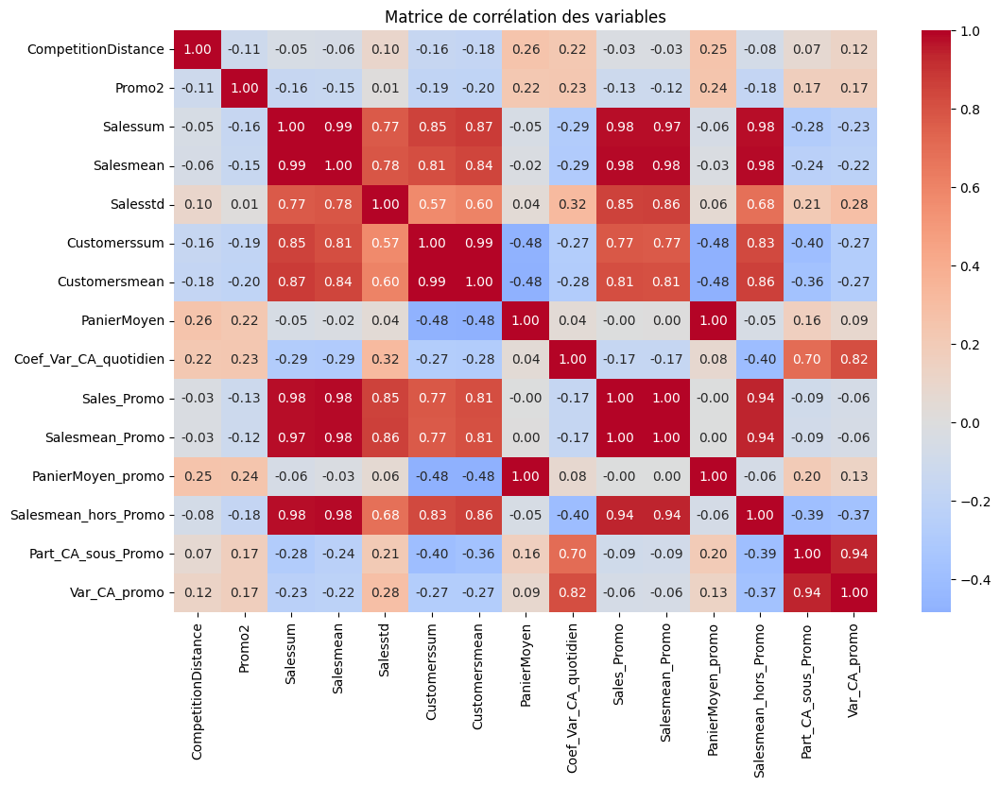

In [93]:
#Affichage matrice des corrélation poura aide au choix des variables
plt.figure(figsize=(12, 8))
sns.heatmap(df_kmean.corr(),annot=True,cmap='coolwarm',center=0, fmt='.2f')
plt.title('Matrice de corrélation des variables')
plt.show()

In [94]:
#Suppression des variables présentants des coef de corrélation élevés
df_kmean = df_kmean.drop(columns=['Salesstd','Salessum' ,'Customerssum','Sales_Promo','Salesmean',  'Customersmean', 'Salesmean_Promo', 'Salesmean_hors_Promo', 'PanierMoyen_promo',"Part_CA_sous_Promo", 'Coef_Var_CA_quotidien'])
df_kmean.head()

,CompetitionDistance,Promo2,PanierMoyen,Var_CA_promo
0,1270.00,0,8.44,22.69
1,570.00,1,8.48,62.45
2,14130.00,1,9.26,64.50
3,620.00,0,7.29,19.23
4,29910.00,0,8.70,73.63


Nous allons pour la suite de l'analyse selectionner les 4 variables suivantes : CompetitionDistance, Promo2, PanierMoyen et Var_CA_promo.

In [95]:
X = df_kmean.copy()

In [96]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
kmeans.fit(X_scaled)

KMeans(n_clusters=4, n_init=20, random_state=42)

In [97]:
#Calcul de l'inertie
inertia = []
k_list = range(1, 10)
for i in k_list:
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=20)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    print(f"K={i} : inertie={kmeans.inertia_:.2f}")

K=1 : inertie=3732.00
K=2 : inertie=2715.97
K=3 : inertie=2140.09
K=4 : inertie=1760.24
K=5 : inertie=1501.05
K=6 : inertie=1294.02
K=7 : inertie=1137.24
K=8 : inertie=1041.83
K=9 : inertie=960.13


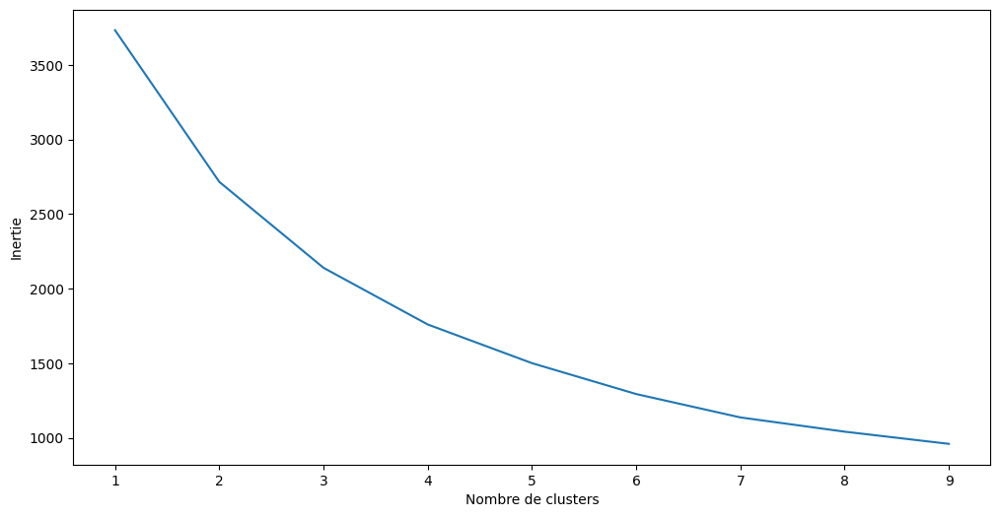

In [98]:
plt.figure(figsize=(12, 6))
plt.plot(k_list, inertia)
plt.ylabel("Inertie")
plt.xlabel("Nombre de clusters")
plt.show()

La méthode du coude suggère un nombre de clusters autour de 3 et 4. Nous allons donc partir sur 4 clusters pour la suite de l'analyse.

In [99]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
kmeans.fit(X_scaled)

KMeans(n_clusters=4, n_init=20, random_state=42)

In [100]:
X["cluster"] = kmeans.labels_

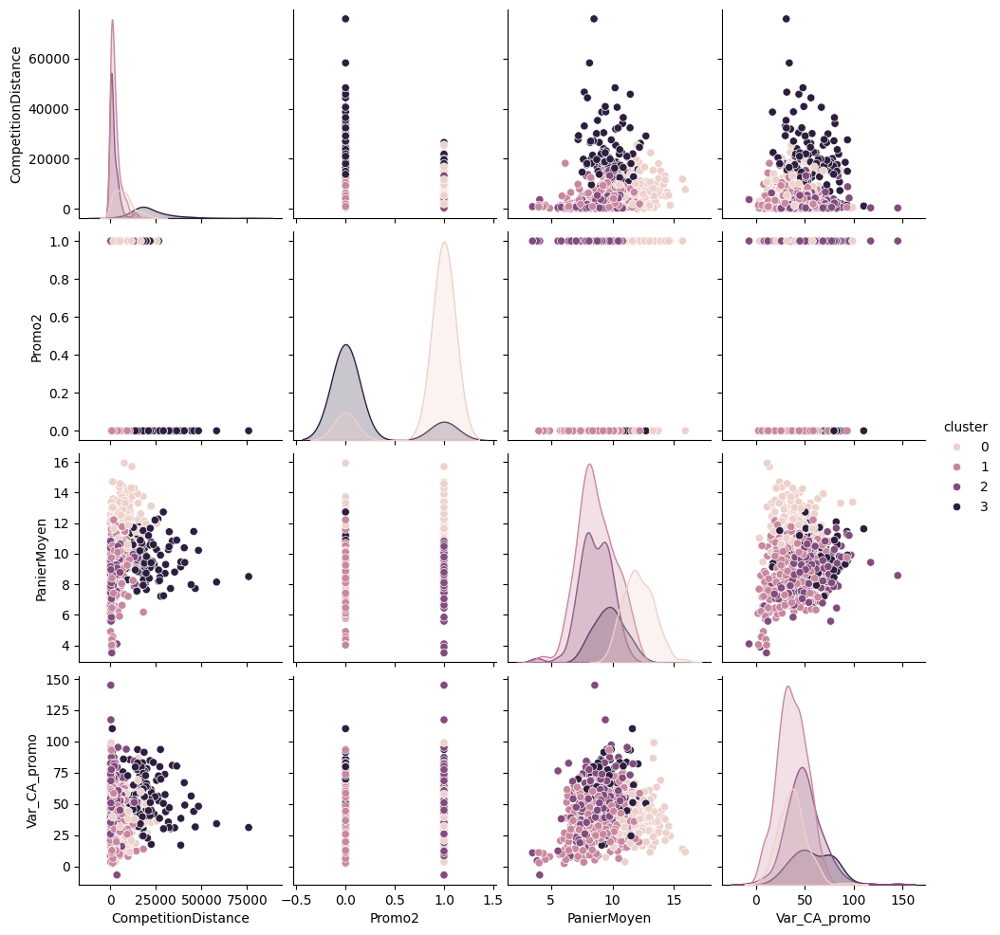

In [101]:
sns.pairplot(X, hue="cluster")

In [102]:
#Regrouper la matrice des clusters en projection ACP pour plus de visibilité
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
X["PC1"] = X_pca[:,0]
X["PC2"] = X_pca[:,1]

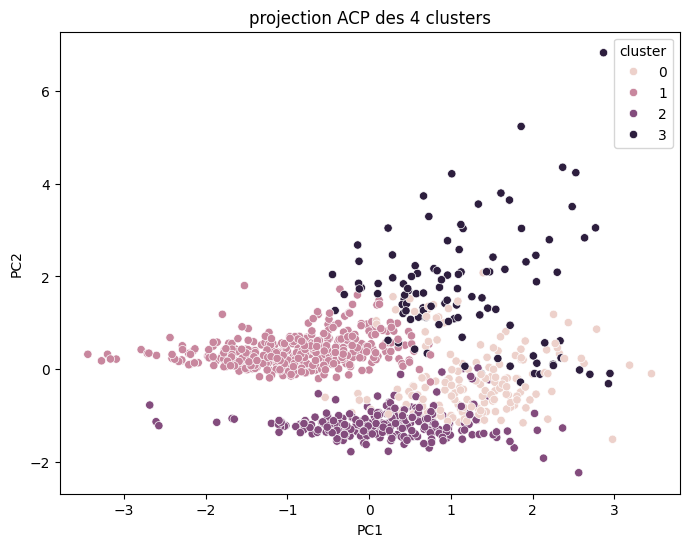

In [103]:
import seaborn as sns
plt.figure(figsize=(8,6))
sns.scatterplot(data=X,x="PC1",y="PC2",hue="cluster")
plt.title("projection ACP des 4 clusters")
plt.show()

In [104]:
#répartition du nombre de magasin par cluster
X['cluster'].value_counts().sort_index()

,count
cluster,
0,169
1,409
2,250
3,105


In [105]:
X.groupby('cluster').mean()

,CompetitionDistance,Promo2,PanierMoyen,Var_CA_promo,PC1,PC2
cluster,,,,,,
0,7352.54,0.88,12.12,37.52,1.24,-0.23
1,2691.91,0.00,8.70,37.23,-0.93,0.38
2,2035.08,1.00,8.61,49.14,0.19,-1.18
3,22183.52,0.16,9.74,57.82,1.17,1.72


In [106]:
#Jonction des DF X et df_merge3 pour rapprocher le numéro de cluster au numéro de Store afin de caractériser les typologies de clusters
df_clusters = df_merge3.join(X["cluster"], how="inner")


In [107]:
#CA moyen et clients moyens par cluster
df_clusters.groupby("cluster")[["Salesmean", "Customersmean"]].mean().round(0)

,Salesmean,Customersmean
cluster,,
0,6934.00,576.00
1,7483.00,893.00
2,6405.00,769.00
3,6585.00,680.00


In [108]:
#Typologie d'assortiement par cluster
#Niveau d'assortiment de la gamme produit : a = assortiment basique, b = assortiment large et c = assortiment très large
Assortment_cluster = df_clusters.pivot_table(index="cluster", columns="Assortment", values="Store", aggfunc="count")
Assortment_cluster


Assortment,a,b,c
cluster,,,
0,52.00,NaN,117.00
1,231.00,5.00,173.00
2,142.00,3.00,105.00
3,52.00,NaN,53.00


In [109]:
#en %
Assortment_cluster = df_clusters.pivot_table(index="cluster", columns="Assortment", values="Store", aggfunc="count")
Assortment_cluster = Assortment_cluster.fillna(0)

Assortment_cluster["Total"] = Assortment_cluster["a"] + Assortment_cluster["b"] + Assortment_cluster["c"]
Assortment_cluster["a_%"] = Assortment_cluster["a"] / Assortment_cluster["Total"] * 100
Assortment_cluster["b_%"] = Assortment_cluster["b"] / Assortment_cluster["Total"] * 100
Assortment_cluster["c_%"] = Assortment_cluster["c"] / Assortment_cluster["Total"] * 100

Assortment_cluster[["a_%", "b_%", "c_%"]]

Assortment,a_%,b_%,c_%
cluster,,,
0,30.77,0.00,69.23
1,56.48,1.22,42.30
2,56.80,1.20,42.00
3,49.52,0.00,50.48


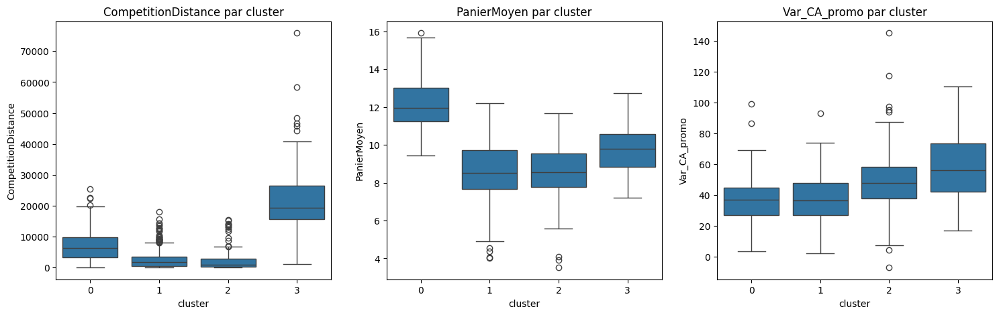

In [110]:
#Affichage des boxplot pour interprétation des clusters
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.boxplot(data=X, x="cluster", y="CompetitionDistance")
plt.title("CompetitionDistance par cluster")

plt.subplot(1, 3, 2)
sns.boxplot(data=X, x="cluster", y="PanierMoyen")
plt.title("PanierMoyen par cluster")

plt.subplot(1, 3, 3)
sns.boxplot(data=X, x="cluster", y="Var_CA_promo")
plt.title("Var_CA_promo par cluster")

plt.show()


**Cluster 0 : Magasins éloignés des concurrents avec le panier moyen le plus élevé**. 169 magasins. Distance moyenne des concurrents de 7.3 KM. Panier moyen de 12.12 EUR. Promo2 présent dans 88 % des magasins et variation du CA associée aux promotions de +37.52 %. Assortiment très large pour 69% des magasins.

**Cluster 1 : Magasins proches des concurrents sans Promo2. 409 magasins, le groupe le plus nombreux**. Distance moyenne des concurrents de 2.7 KM. Panier moyen de 8.70 EUR. Aucun magasin ne participe à Promo2 et variation du CA associée aux promotions de +37.23 %. Assortiment basique pour 56 % des magasins

**Cluster 2 : Magasins très proches des concurrents avec Promo2 et le panier moyen le plus faible** . 250 magasins. Distance moyenne des concurrents de 2.0 KM. Panier moyen de 8.61 EUR. Promo2 présent dans tous les magasins et variation du CA associée aux promotions de +49.14 %. Assortiment basique pour 57% des magasins.

**Cluster 3 : Magasins très éloignés des concurrents 105 magasins, le groupe le moins nombreux**. Distance moyenne des concurrents de 22.2 KM. Panier moyen de 9.74 EUR. Promo2 présent dans 16 % des magasins et variation du CA associée aux promotions de +57.82 %. Assortiment basique et très large 50% chacun

# 3. Construction d'un modèle de prévision des ventes

## 3.1 Préparation du jeu de données pour entraîner le modèle

In [111]:
#Selection aléatoire de 4 magasins pour entraîner le modèle
df_clusters[["Store", "cluster"]]
magasins_aleatoires = df_clusters.groupby("cluster").sample(n=1, random_state=42)
magasins_aleatoires[["Store", "cluster"]]

,Store,cluster
727,871,0
248,304,1
328,391,2
650,783,3


In [112]:
#Préparation des 4 DF

df_871 = df_train.loc[df_train['Store'] == 871, ['Date', 'Sales']]
df_871 = df_871.set_index('Date')
df_871 = df_871.sort_index()

df_304 = df_train.loc[df_train['Store'] == 304, ['Date', 'Sales']]
df_304 = df_304.set_index('Date')
df_304 = df_304.sort_index()

df_391 = df_train.loc[df_train['Store'] == 391, ['Date', 'Sales']]
df_391 = df_391.set_index('Date')
df_391 = df_391.sort_index()

df_783 = df_train.loc[df_train['Store'] == 783, ['Date', 'Sales']]
df_783 = df_783.set_index('Date')
df_783 = df_783.sort_index()


## 3.2 Entraînement du modèle : moyenne mobile sur 15 jours

In [113]:
#Magasin 871
features_daily_871 = pd.DataFrame({"y": df_871["Sales"].sort_index()})
#Séparation Train / Test
train_871 = features_daily_871.loc[:'2014-12-31'].copy()
test_871 = features_daily_871.loc['2015-01-01':'2015-06-30'].copy()
#MM 15 jours sur le Train (pour le graphique)
train_871["ma_15d"] = train_871["y"].rolling(window=15).mean()
#Prévision : moyenne des 15 derniers jours du Train, répétée sur tout le Test
valeur_prev_871 = train_871["y"].tail(15).mean()
test_871["ventes_reelles"] = test_871["y"]
test_871["ma_prev_15d"] = valeur_prev_871

#Magasin 304
features_daily_304 = pd.DataFrame({"y": df_304["Sales"].sort_index()})
train_304 = features_daily_304.loc[:'2014-12-31'].copy()
test_304 = features_daily_304.loc['2015-01-01':'2015-06-30'].copy()
train_304["ma_15d"] = train_304["y"].rolling(window=15).mean()
valeur_prev_304 = train_304["y"].tail(15).mean()
test_304["ventes_reelles"] = test_304["y"]
test_304["ma_prev_15d"] = valeur_prev_304

#Magasin 391
features_daily_391 = pd.DataFrame({"y": df_391["Sales"].sort_index()})
train_391 = features_daily_391.loc[:'2014-12-31'].copy()
test_391 = features_daily_391.loc['2015-01-01':'2015-06-30'].copy()
train_391["ma_15d"] = train_391["y"].rolling(window=15).mean()
valeur_prev_391 = train_391["y"].tail(15).mean()
test_391["ventes_reelles"] = test_391["y"]
test_391["ma_prev_15d"] = valeur_prev_391

#Magasin 783
features_daily_783 = pd.DataFrame({"y": df_783["Sales"].sort_index()})
train_783 = features_daily_783.loc[:'2014-12-31'].copy()
test_783 = features_daily_783.loc['2015-01-01':'2015-06-30'].copy()
train_783["ma_15d"] = train_783["y"].rolling(window=15).mean()
valeur_prev_783 = train_783["y"].tail(15).mean()
test_783["ventes_reelles"] = test_783["y"]
test_783["ma_prev_15d"] = valeur_prev_783


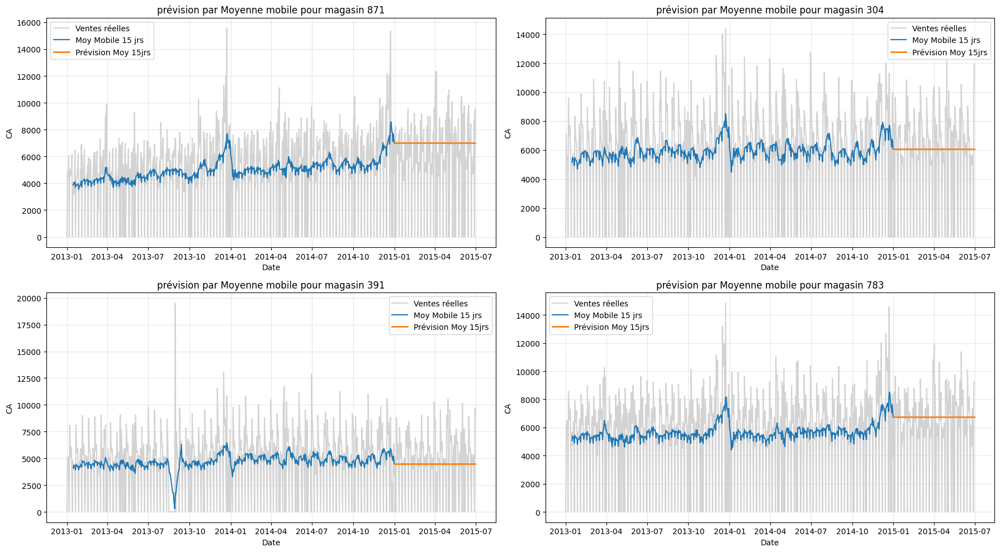

In [114]:
plt.figure(figsize=(18, 10))

#Magasin 871
plt.subplot(2, 2, 1)
plt.plot(train_871.index, train_871["y"],color="lightgrey", label="Ventes réelles")
plt.plot(test_871.index, test_871["ventes_reelles"], color="lightgrey")
plt.plot(train_871.index, train_871["ma_15d"], label="Moy Mobile 15 jrs")
plt.plot(test_871.index, test_871["ma_prev_15d"], linewidth=2, label="Prévision Moy 15jrs")
plt.title("prévision par Moyenne mobile pour magasin 871")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

#Magasin 304
plt.subplot(2, 2, 2)
plt.plot(train_304.index, train_304["y"], color="lightgrey", label="Ventes réelles")
plt.plot(test_304.index, test_304["ventes_reelles"], color="lightgrey")
plt.plot(train_304.index, train_304["ma_15d"], label="Moy Mobile 15 jrs")
plt.plot(test_304.index, test_304["ma_prev_15d"], linewidth=2, label="Prévision Moy 15jrs")
plt.title("prévision par Moyenne mobile pour magasin 304")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

#Magasin 391
plt.subplot(2, 2, 3)
plt.plot(train_391.index, train_391["y"], color="lightgrey", label="Ventes réelles")
plt.plot(test_391.index, test_391["ventes_reelles"], color="lightgrey")
plt.plot(train_391.index, train_391["ma_15d"], label="Moy Mobile 15 jrs")
plt.plot(test_391.index, test_391["ma_prev_15d"], linewidth=2, label="Prévision Moy 15jrs")
plt.title("prévision par Moyenne mobile pour magasin 391")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

#Magasin 783
plt.subplot(2, 2, 4)
plt.plot(train_783.index, train_783["y"], color="lightgrey", label="Ventes réelles")
plt.plot(test_783.index, test_783["ventes_reelles"], color="lightgrey")
plt.plot(train_783.index, train_783["ma_15d"], label="Moy Mobile 15 jrs")
plt.plot(test_783.index, test_783["ma_prev_15d"], linewidth=2, label="Prévision Moy 15jrs")
plt.title("prévision par Moyenne mobile pour magasin 783")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3.3 Test d'une deuxième approche de modélisation : Prophet

In [115]:
#Préparation des données en ajoutant les variables Promo et Open
#Magasin 871
df_871_prophet = df_train.loc[df_train["Store"] == 871, ["Date", "Sales", "Promo", "Open"]].sort_values("Date")
df_871_prophet.columns = ["ds", "y", "Promo", "Open"]
#Train jusqu'au 31/12/2014 et test 01/01 au 30/06/2015
train_871_prophet = df_871_prophet.loc[df_871_prophet["ds"] <= "2014-12-31"].copy()
test_871_prophet = df_871_prophet.loc[(df_871_prophet["ds"] >= "2015-01-01") & (df_871_prophet["ds"] <= "2015-06-30")].copy()

#Magasin 304
df_304_prophet = df_train.loc[df_train["Store"] == 304, ["Date", "Sales", "Promo", "Open"]].sort_values("Date")
df_304_prophet.columns = ["ds", "y", "Promo", "Open"]
train_304_prophet = df_304_prophet.loc[df_304_prophet["ds"] <= "2014-12-31"].copy()
test_304_prophet = df_304_prophet.loc[(df_304_prophet["ds"] >= "2015-01-01") & (df_304_prophet["ds"] <= "2015-06-30")].copy()

#Magasin 391
df_391_prophet = df_train.loc[df_train["Store"] == 391, ["Date", "Sales", "Promo", "Open"]].sort_values("Date")
df_391_prophet.columns = ["ds", "y", "Promo", "Open"]
train_391_prophet = df_391_prophet.loc[df_391_prophet["ds"] <= "2014-12-31"].copy()
test_391_prophet = df_391_prophet.loc[(df_391_prophet["ds"] >= "2015-01-01") & (df_391_prophet["ds"] <= "2015-06-30")].copy()

#Magasin 783
df_783_prophet = df_train.loc[df_train["Store"] == 783, ["Date", "Sales", "Promo", "Open"]].sort_values("Date")
df_783_prophet.columns = ["ds", "y", "Promo", "Open"]
train_783_prophet = df_783_prophet.loc[df_783_prophet["ds"] <= "2014-12-31"].copy()
test_783_prophet = df_783_prophet.loc[(df_783_prophet["ds"] >= "2015-01-01") & (df_783_prophet["ds"] <= "2015-06-30")].copy()

In [116]:
from prophet import Prophet

#Magasin 871
model_871 = Prophet(yearly_seasonality=True)
model_871.add_regressor("Promo")
model_871.add_regressor("Open")
model_871.fit(train_871_prophet)
future_871 = test_871_prophet[["ds", "Promo", "Open"]]
forecast_871 = model_871.predict(future_871)

#Magasin 304
model_304 =  Prophet(yearly_seasonality=True)
model_304.add_regressor("Promo")
model_304.add_regressor("Open")
model_304.fit(train_304_prophet)
future_304 = test_304_prophet[["ds", "Promo", "Open"]]
forecast_304 = model_304.predict(future_304)


#Magasin 391
model_391 =  Prophet(yearly_seasonality=True)
model_391.add_regressor("Promo")
model_391.add_regressor("Open")
model_391.fit(train_391_prophet)
future_391 = test_391_prophet[["ds", "Promo", "Open"]]
forecast_391 = model_391.predict(future_391)


#Magasin 783
model_783 =  Prophet(yearly_seasonality=True)
model_783.add_regressor("Promo")
model_783.add_regressor("Open")
model_783.fit(train_783_prophet)
future_783 = test_783_prophet[["ds", "Promo", "Open"]]
forecast_783 = model_783.predict(future_783)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


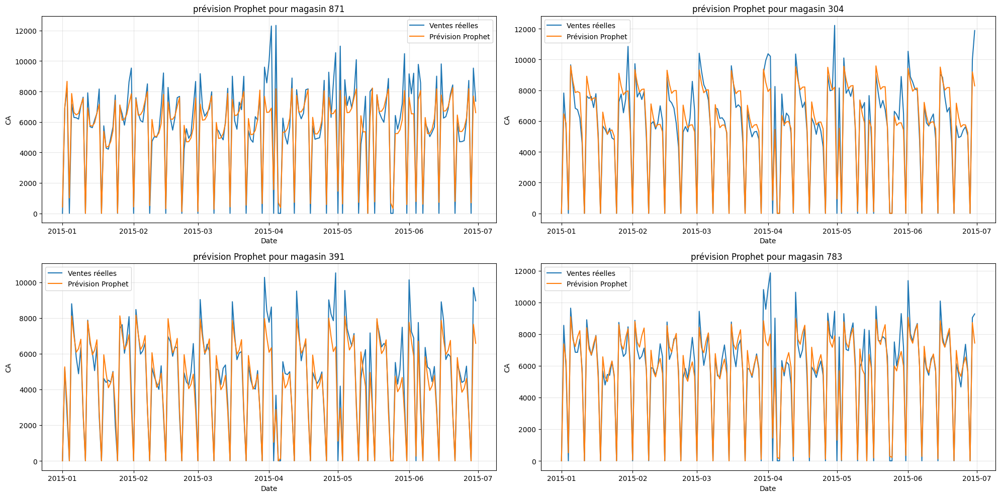

In [117]:
#Ajout des prévisions dans chaque DataFrame
test_871_prophet["prevision"] = forecast_871["yhat"].clip(lower=0).values
test_304_prophet["prevision"] = forecast_304["yhat"].clip(lower=0).values
test_391_prophet["prevision"] = forecast_391["yhat"].clip(lower=0).values
test_783_prophet["prevision"] = forecast_783["yhat"].clip(lower=0).values


plt.figure(figsize=(20, 10))

#Magasin 871
plt.subplot(2, 2, 1)
plt.plot(test_871_prophet["ds"], test_871_prophet["y"], label="Ventes réelles")
plt.plot(test_871_prophet["ds"], test_871_prophet["prevision"], label="Prévision Prophet")
plt.title("prévision Prophet pour magasin 871")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

#Magasin 304
plt.subplot(2, 2, 2)
plt.plot(test_304_prophet["ds"], test_304_prophet["y"], label="Ventes réelles")
plt.plot(test_304_prophet["ds"], test_304_prophet["prevision"], label="Prévision Prophet")
plt.title("prévision Prophet pour magasin 304")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

#Magasin 391
plt.subplot(2, 2, 3)
plt.plot(test_391_prophet["ds"], test_391_prophet["y"], label="Ventes réelles")
plt.plot(test_391_prophet["ds"], test_391_prophet["prevision"], label="Prévision Prophet")
plt.title("prévision Prophet pour magasin 391")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

#Magasin 783
plt.subplot(2, 2, 4)
plt.plot(test_783_prophet["ds"], test_783_prophet["y"], label="Ventes réelles")
plt.plot(test_783_prophet["ds"], test_783_prophet["prevision"], label="Prévision Prophet")
plt.title("prévision Prophet pour magasin 783 ")
plt.xlabel("Date")
plt.ylabel("CA")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 4. Évaluez la performance du modèle de prévision sur les différents groupes de magasins

In [118]:
from sklearn.metrics import mean_absolute_error

#Nous allons partir que la métric MAE car elle mesure l'écart absolu moyen entre les ventes réelles et les ventes prédites. Plus la MAE est faible, plus les prévisions sont proches des ventes réelles.

# Magasin 871
mae_baseline_871 = mean_absolute_error(test_871["y"], test_871["ma_prev_15d"])
mae_prophet_871 = mean_absolute_error(test_871_prophet["y"], test_871_prophet["prevision"])
print("Magasin 871")
print("MAE Baseline :", mae_baseline_871)
print("MAE Prophet :", mae_prophet_871)


# Magasin 304
mae_baseline_304 = mean_absolute_error(test_304["y"], test_304["ma_prev_15d"])
mae_prophet_304 = mean_absolute_error(test_304_prophet["y"], test_304_prophet["prevision"])
print("\nMagasin 304")
print("MAE Baseline :", mae_baseline_304)
print("MAE Prophet :", mae_prophet_304)

# Magasin 391
mae_baseline_391 = mean_absolute_error(test_391["y"], test_391["ma_prev_15d"])
mae_prophet_391 = mean_absolute_error(test_391_prophet["y"], test_391_prophet["prevision"])
print("\nMagasin 391")
print("MAE Baseline :", mae_baseline_391)
print("MAE Prophet :", mae_prophet_391)

# Magasin 783
mae_baseline_783 = mean_absolute_error(test_783["y"], test_783["ma_prev_15d"])
mae_prophet_783 = mean_absolute_error(test_783_prophet["y"], test_783_prophet["prevision"])
print("\nMagasin 783")
print("MAE Baseline :", mae_baseline_783)
print("MAE Prophet :", mae_prophet_783)

Magasin 871
MAE Baseline : 2404.2629834254144
MAE Prophet : 720.6444425034301

Magasin 304
MAE Baseline : 2265.390055248619
MAE Prophet : 643.6908135717161

Magasin 391
MAE Baseline : 2260.7163904235726
MAE Prophet : 540.4526265018808

Magasin 783
MAE Baseline : 2152.8618784530386
MAE Prophet : 547.4396599665354


Magasin 871 :
- Baseline : MAE de 2404EUR. En moyenne les prévisions s'écartent des ventes réelles de 2404EUR par jour.
- Prophet : MAE de 720 EUR. L'écart moyen entre les prévisions et les ventes réelles est de 720 EUR par jour.

In [119]:
#Magasin 871
variation_mae_871 = (mae_baseline_871 - mae_prophet_871) / mae_baseline_871 * 100
print("Magasin 871 : Prophet réduit la MAE de", round(variation_mae_871, 2), "% par rapport à la baseline.")

#Magasin 304
variation_mae_304 = (mae_baseline_304 - mae_prophet_304) / mae_baseline_304 * 100
print("Magasin 304 : Prophet réduit la MAE de", round(variation_mae_304, 2), "% par rapport à la baseline.")

#Magasin 391
variation_mae_391 = (mae_baseline_391 - mae_prophet_391) / mae_baseline_391 * 100
print("Magasin 391 : Prophet réduit la MAE de", round(variation_mae_391, 2), "% par rapport à la baseline.")

#Magasin 783
variation_mae_783 = (mae_baseline_783 - mae_prophet_783) / mae_baseline_783 * 100
print("Magasin 783 : Prophet réduit la MAE de", round(variation_mae_783, 2), "% par rapport à la baseline.")

Magasin 871 : Prophet réduit la MAE de 70.03 % par rapport à la baseline.
Magasin 304 : Prophet réduit la MAE de 71.59 % par rapport à la baseline.
Magasin 391 : Prophet réduit la MAE de 76.09 % par rapport à la baseline.
Magasin 783 : Prophet réduit la MAE de 74.57 % par rapport à la baseline.


Sur les 4 magasins issus des 4 clusters, le modèle Prophet a une MAE plus faible que la baseline. Le modèle Prophet a donc des prévisions plus proches des ventes réelles. Il s'agit du meilleur modèle parmi les 2 testés.